# 연습문제 2-9 ~ 2-10 풀이: 출력이 여럿인 퍼셉트론, 퍼셉트론의 한계(XOR)

2-3절 연습문제 2-9 ~ 2-10의 풀이 예시다. 정답이 하나뿐인 문제가 아니므로 다른 방법으로도 구현할 수 있다.

- 본문 예제 코드는 `code_examples/ch02/` 아래 예제 노트북을 참고한다.

In [1]:
# 공통 라이브러리와 torch 라이브러리 임포트
import sys
sys.path.append('../../')                   # 공통 라이브러리가 있는 저장소 최상위 폴더

import torch
import torch.nn as nn
import torch.optim as optim
from code_reference import common
from code_reference import visualize as viz

viz.configure(save_grayscale=False)         # 시각화 결과를 파일에 저장하지 않음
common.set_korean_plot_env()                # matplotlib에서 한글 폰트 사용

## 사전 준비

2-3절의 `Perceptron` 클래스([코드 2-10])와 학습 루프([코드 2-16])를 가져온다.
학습 로그는 출력하지 않고 마지막 손실만 돌려주는 조용한 학습 함수를 사용한다.
0.5를 문턱값으로 모든 샘플을 바르게 분류하면 정상 모델이 만들어진 것으로 판단한다.

In [2]:
class Perceptron(nn.Module):                        # 본문 [코드 2-10]
    def __init__(self, in_features, out_features):
        super().__init__()
        self.linear_layer = nn.Linear(in_features, out_features)
        self.activation = nn.Sigmoid()

    def forward(self, x):
        return self.activation(self.linear_layer(x))

X = torch.tensor([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])    # (4, 2): 입력
SEED = 2            # 초깃값을 재현할 수 있도록 고정하는 시드

In [3]:
def train_quiet(model, X, Y_true, epochs, lr=0.1):
    """[코드 2-16]과 같은 고수준 API 학습 루프. 마지막 손실만 반환한다."""
    criterion = nn.MSELoss()
    optimizer = optim.SGD(model.parameters(), lr=lr)
    model.train()                           # 학습 모드 선언
    for _ in range(epochs):
        loss = criterion(model(X), Y_true)  # 순전파와 손실 계산
        optimizer.zero_grad()               # 기울기 초기화
        loss.backward()                     # 역전파
        optimizer.step()                    # 파라미터 최적화
    model.eval()                            # 평가 모드 선언
    return loss.item()

## 연습문제 2-9

> 0과 1의 조합을 입력받아, 한 출력은 AND 게이트를, 다른 출력은 OR 게이트를 시뮬레이션하는
> 모델을 만들어 보자. 이 모델은 입력 두 개와 출력 두 개를 가진다.

**정답 텐서를 (4, 2) 형태로 만들고 뉴런 두 개로 학습하기**
- 이 문제의 입력값과 출력값에 해당되는 진리표는 다음과 같다.
  | x1 | x2 | y1(AND 게이트 출력) | y2(OR 게이트 출력) |
  |---|---|---|---|
  | 0 | 0 | 0 | 0 |
  | 0 | 1 | 0 | 1 |
  | 1 | 0 | 0 | 1 |
  | 1 | 1 | 1 | 1 |
  
- 출력이 두 개이므로 정답 텐서는 열 하나가 AND, 다른 열이 OR인 (4, 2) 형태
- `Perceptron(2, 2)`: `nn.Linear(2, 2)`의 뉴런이 두 개이고 같은 두 입력을 공유
- 학습률 0.1, 1,000 에포크는 2-3절 본문 예제와 같은 값을 사용

In [4]:
Y2 = torch.tensor([[0., 0.], [0., 1.], [0., 1.], [1., 1.]])   # (4, 2): [AND, OR] 정답

def train_and_or(epochs):
    torch.manual_seed(SEED)
    model = Perceptron(2, 2)                        # 입력 2개, 출력 2개
    loss = train_quiet(model, X, Y2, epochs)
    return model, loss

def show(model, loss):
    with torch.no_grad():
        Y_pred = model(X)
    print(f'손실 {loss:.4f}, 분류 성공 {torch.equal((Y_pred >= 0.5).float(), Y2)}')
    print('입력      AND 출력  OR 출력')
    for x, y in zip(X.tolist(), Y_pred.tolist()):
        print(f'{str(tuple(int(v) for v in x)):8}  {y[0]:8.3f} {y[1]:8.3f}')

In [5]:
model, loss = train_and_or(1000)
show(model, loss)

손실 0.0825, 분류 성공 True
입력      AND 출력  OR 출력
(0, 0)       0.130    0.420
(0, 1)       0.307    0.782
(1, 0)       0.318    0.791
(1, 1)       0.580    0.949


**결과 분석: 성공하지만 두 출력 모두 문턱값에 가깝다**
- 네 샘플을 모두 바르게 분류해 성공
- AND의 (1, 1) 출력은 0.58, OR의 (0, 0) 출력은 0.42: 문턱값 0.5까지 여유가 0.08씩이라 두 출력 모두 간신히 분류에 성공
- 여유가 가장 작은 샘플은 두 출력 모두 다른 세 샘플과 정답이 다른 샘플(AND는 (1, 1), OR는 (0, 0))

**에포크를 늘려 다시 학습하고 뉴런별 가중치 비교하기**
- 에포크를 3,000으로 늘린 후 분류 결과가 더 분명하게 바뀌었는지를 확인
- 선형 계층의 가중치는 (2, 2) 형태로 행 하나가 뉴런 하나: 두 뉴런이 학습한 값을 비교

In [6]:
model, loss = train_and_or(3000)
show(model, loss)

weight = model.linear_layer.weight.detach()         # (2, 2): 행 하나가 뉴런 하나
bias = model.linear_layer.bias.detach()
for name, w, b in zip(('AND', 'OR'), weight, bias):
    print(f'{name:>3} 뉴런: 가중치 ({w[0]:.2f}, {w[1]:.2f}), 편향 {b:.2f}')

손실 0.0341, 분류 성공 True
입력      AND 출력  OR 출력
(0, 0)       0.029    0.244
(0, 1)       0.221    0.856
(1, 0)       0.221    0.858
(1, 1)       0.728    0.991
AND 뉴런: 가중치 (2.25, 2.24), 편향 -3.51
 OR 뉴런: 가중치 (2.93, 2.92), 편향 -1.13


**결과 확인: 뉴런마다 자기 결정 경계를 따로 학습한다**
- 3,000 에포크에서 AND의 (1, 1) 출력은 0.73으로 올라가고 OR의 (0, 0) 출력은 0.24로 내려가 분류가 더 분명해짐
- 두 뉴런은 서로 다른 가중치와 편향을 학습: 하나의 계층 안에서 서로 다른 분류기 두 개가 동시에 학습
- AND 뉴런은 편향이 -3.51로 더 작아 두 입력이 모두 켜져야 출력이 켜지고, OR 뉴런은 편향이 -1.13이라 입력 하나로도 켜짐

## 연습문제 2-10

> XOR 게이트는 두 입력이 같으면 0을, 다르면 1을 출력한다.
> 이 XOR 게이트를 시뮬레이션하는 퍼셉트론 모델을 만들어 보자.
>
> 만약 학습된 퍼셉트론의 분류 결과가 좋지 않다면, 그 이유가 무엇일지 추론해 제시해 보자.
> 참고로 퍼셉트론 모델로 이 데이터를 제대로 분류할 수 없으며,
> 이를 극복하는 것이 다음 3장의 주요 목표 중 하나다.

**XOR 학습하기**
- 정답은 두 입력이 다를 때만 1: (0, 0)과 (1, 1)은 0, (0, 1)과 (1, 0)은 1
- 에포크를 1,000, 5,000, 20,000으로 늘려 가며 손실과 네 샘플의 출력을 확인

In [7]:
Y_xor = torch.tensor([[0.], [1.], [1.], [0.]])      # 두 입력이 다를 때만 1

print('  에포크     손실   네 샘플의 출력')
for epochs in (1000, 5000, 20000):
    torch.manual_seed(SEED)
    model = Perceptron(2, 1)
    loss = train_quiet(model, X, Y_xor, epochs)
    with torch.no_grad():
        out = [round(v, 3) for v in model(X).flatten().tolist()]
    print(f'{epochs:8,d} {loss:8.4f}   {out}')

  에포크     손실   네 샘플의 출력
   1,000   0.2500   [0.503, 0.499, 0.502, 0.498]
   5,000   0.2500   [0.5, 0.5, 0.5, 0.5]
  20,000   0.2500   [0.5, 0.5, 0.5, 0.5]


**결과 분석: 손실이 0.25에서 멈추고 출력이 모두 0.5가 된다**
- 에포크를 20배로 늘려도 손실은 0.2500에서 더 내려가지 않음
- 네 샘플의 출력이 모두 0.5로 모임: 입력과 무관하게 같은 값만 내놓는 상태
- 출력이 모두 0.5이면 오차가 샘플마다 0.5이고 제곱하면 0.25, 평균도 0.25: 손실이 정확히 0.25인 이유

**원인 찾기: 네 점을 좌표평면에 찍어 보기**
- 정답이 1인 점은 채운 원, 0인 점은 빈 원으로 표시
- 퍼셉트론의 결정 경계는 직선 하나: 직선으로 두 종류의 점을 가를 수 있는지 확인

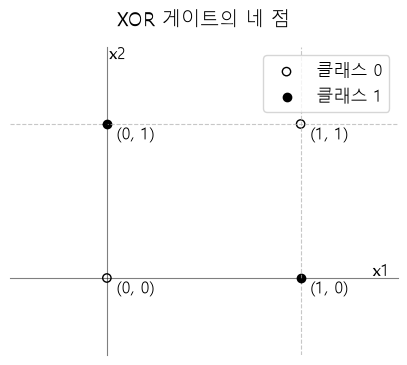

In [8]:
x1_list = X[:, 0].int().tolist()            # 네 입력의 x1, x2 좌표
x2_list = X[:, 1].int().tolist()
y_list = Y_xor.flatten().int().tolist()     # 정답: 두 입력이 다를 때만 1
viz.plot_decision_boundary(
    (x1_list, x2_list, y_list), title='XOR 게이트의 네 점',
    x_label='x1', y_label='x2', figsize=(5, 4),
)

**결과 분석: 직선 하나로는 대각선의 두 점을 가를 수 없다**
- 정답이 1인 두 점 (0, 1)과 (1, 0)이 대각선으로 마주 보고, 0인 두 점도 반대편 대각선에 있음
- 어떤 직선을 그어도 같은 종류의 두 점을 한쪽에 모을 수 없음
- AND, OR, NAND는 점 하나만 떼어 내면 되므로 직선으로 가능했지만 XOR은 불가능: 이것이 퍼셉트론의 한계

**시드를 바꿔 10번 학습하기**
- 초깃값 때문에 실패한 것이 아닌지 시드를 1부터 10까지 바꿔 5,000 에포크씩 학습

In [9]:
results = []
for seed in range(1, 11):
    torch.manual_seed(seed)
    model = Perceptron(2, 1)
    loss = train_quiet(model, X, Y_xor, 5000)
    with torch.no_grad():
        ok = torch.equal((model(X) >= 0.5).float(), Y_xor)
    results.append((loss, ok))

success = sum(ok for _, ok in results)
losses = [loss for loss, _ in results]
print(f'시드 1~10: 분류 성공 {success}번, 손실 {min(losses):.4f} ~ {max(losses):.4f}')

시드 1~10: 분류 성공 0번, 손실 0.2500 ~ 0.2500


**확인**
- 시드를 10번 바꿔도 분류에 성공한 경우가 없고 손실은 모두 0.25
- 초깃값이나 에포크의 문제가 아니라 모델 구조의 한계
- 3장의 다층 퍼셉트론은 은닉층으로 결정 경계를 여러 개 조합해 이 한계를 넘음

**직접 해 보기: x1 * x2의 값을 세 번째 입력으로 추가하면?**
- 입력을 (x1, x2, x1 * x2) 세 개로 늘려 `Perceptron(3, 1)`로 XOR을 학습
- 같은 퍼셉트론인데 달라지는 점이 있을까?

In [10]:
X_new = torch.cat([X, X[:, :1] * X[:, 1:]], dim=1)  # (4, 3): x1, x2, x1 * x2
torch.manual_seed(SEED)
model = Perceptron(3, 1)
loss = train_quiet(model, X_new, Y_xor, 5000)
with torch.no_grad():
    Y_pred = model(X_new)

print(f'손실 {loss:.4f}, 분류 성공 {torch.equal((Y_pred >= 0.5).float(), Y_xor)}')
print('네 샘플의 출력:', [round(v, 3) for v in Y_pred.flatten().tolist()])
w = model.linear_layer.weight.detach().flatten().tolist()
print(f'가중치 (x1, x2, x1 * x2): ({w[0]:.2f}, {w[1]:.2f}, {w[2]:.2f})')

손실 0.0201, 분류 성공 True
네 샘플의 출력: [0.174, 0.862, 0.862, 0.11]
가중치 (x1, x2, x1 * x2): (3.39, 3.39, -7.31)


**확인**
- x1 * x2를 입력에 더하면 같은 퍼셉트론이 XOR을 학습: 입력이 3개이면 결정 경계가 평면이 되어 네 점을 가를 수 있음
- 학습된 가중치는 x1, x2에 양수(3.39), x1 * x2에 큰 음수(-7.31): 두 입력이 모두 1일 때 x1 * x2가 합을 눌러 출력을 0으로 되돌림
- 한계는 직선 하나라는 구조에서 나오며, 입력을 다르게 표현하면 달라질 수 있음
- 3장의 모델 구조(다층 퍼셉트론)는 이런 새로운 입력(x1 * x2 같은 조합)을 따로 추가하지 않아도 학습을 통해 구분 가능한 결정 경계를 스스로 만들어 냄